# Create DSM from LAS Point Cloud

This notebook demonstrates how to create Digital Surface Models (DSM) from LAS/LAZ files using the `dsm_lidar` module.

**Features:**
- estimate runtime
- create DSM GeoTIFFs from LAS/LAZ using PDAL
- batch/parallel processing
- load DSMs with `rioxarray` for chunked analytics + quick visualization

> Tip: keep DSM creation (PDAL) and DSM analysis (xarray/dask) in separate sections so you can re-run analytics without regenerating rasters.


In [ ]:
# Notebook setup: import (and hot-reload) the local module

import sys

from pathlib import Path

import importlib



# Navigate to the parent directory where dsm_lidar.py is located

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

if str(PROJECT_ROOT) not in sys.path:

    sys.path.insert(0, str(PROJECT_ROOT))



import dsm_lidar

importlib.reload(dsm_lidar)



from dsm_lidar import (

    estimate_processing_time,

    recommend_dsm_resolution,

    create_dsm,

    batch_create_dsm,

    batch_create_dsm_parallel,

    load_dsm_xarray,

    job_from_config,

    SITE_CONFIGS,

)



print("✅ dsm_lidar module imported successfully")

print("📦 Available functions:")

print([

    "create_dsm",

    "batch_create_dsm",

    "batch_create_dsm_parallel",

    "estimate_processing_time",

    "recommend_dsm_resolution",

    "load_dsm_xarray",

    "compare_dsms",

    "dsm_difference",

    "write_dsm_stac_item",

])


✅ dsm_lidar module imported successfully
📦 Available functions:
['create_dsm', 'batch_create_dsm', 'batch_create_dsm_parallel', 'estimate_processing_time', 'load_dsm_xarray', 'compare_dsms', 'dsm_difference', 'write_dsm_stac_item']


## 1) Estimate processing time and choose resolution



Use this before you commit to a very fine resolution. The helper below tests candidate resolutions and selects the finest one that stays within your time and grid-cell limits.

In [ ]:
# Pick the finest DSM resolution that stays within processing limits.

# Adjust this path or load it from your copied YAML config.

las_file = "/data/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid.las"



candidate_resolutions = [0.10, 0.05, 0.03]

max_estimated_minutes = 15.0

max_grid_cells = 250_000_000



recommendation = recommend_dsm_resolution(

    las_input=las_file,

    candidate_resolutions=candidate_resolutions,

    max_estimated_minutes=max_estimated_minutes,

    max_grid_cells=max_grid_cells,

)

selected_resolution = recommendation["selected_resolution"]



print("=" * 70)

print("AUTOMATIC DSM RESOLUTION SELECTION")

print("=" * 70)

print(f"Limits: <= {max_estimated_minutes:.1f} min and <= {max_grid_cells:,} grid cells")



for est in recommendation["estimates"]:

    res = est["resolution"]

    status = "✅ selected" if res == selected_resolution else ("OK" if est["within_limits"] else "too heavy")

    print(f"\nResolution: {res:.2f} m ({res*100:.0f} cm) [{status}]")

    if "point_count" in est:

        try:

            print(f"  Point count:  {int(est.get('point_count', 0)):,}")

        except Exception:

            print(f"  Point count:  {est.get('point_count')}")

    if "grid_cells" in est:

        print(f"  Grid size:    {int(est['grid_cols']):,} × {int(est['grid_rows']):,}")

        print(f"  Total cells:  {int(est['grid_cells']):,}")

    print(f"  File size:    {est.get('file_size_mb', float('nan')):.1f} MB")

    print(f"  Est. time:    ~{est.get('estimated_minutes', float('nan')):.1f} min")



print(f"\nSelected DSM resolution: {selected_resolution:.2f} m ({selected_resolution*100:.0f} cm)")


PROCESSING TIME ESTIMATES

Resolution: 0.10 m (10 cm)
  Point count:  285,786,198
  Grid size:    3,969 × 4,779
  Total cells:  18,967,851
  File size:    9266.6 MB
  Est. time:    ~0.9 min



Resolution: 0.05 m (5 cm)
  Point count:  285,786,198
  Grid size:    7,939 × 9,559
  Total cells:  75,888,901
  File size:    9266.6 MB
  Est. time:    ~3.8 min

Resolution: 0.03 m (3 cm)
  Point count:  285,786,198
  Grid size:    13,232 × 15,931
  Total cells:  210,798,992
  File size:    9266.6 MB
  Est. time:    ~10.5 min


## 2) Create a single DSM

This runs a PDAL pipeline and writes a tiled GeoTIFF.

In [ ]:
las_input = las_file

resolution_cm = int(round(selected_resolution * 100))

dsm_output = f"/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_{resolution_cm:02d}cm.tif"



create_dsm(

    las_input=las_input,

    dsm_output=dsm_output,

    resolution=selected_resolution,

    output_type="max",    # max Z per cell

    nodata=-9999.0,

    verbose=True,

)


## 3) Batch processing (optional)

Use sequential batch when you want simplicity, and parallel batch when you have multiple files and CPU cores available.

In [ ]:
# Sequential batch example: edit the batch paths in the local config first.
config = dsm_lidar.load_dsm_config(PROJECT_ROOT / "configs" / "dsm_job.local.yml")
pairs = config["batch"]

results = batch_create_dsm(
    input_output_pairs=pairs,
    resolution=config["resolution"],
    output_type=config["output_type"],
)

print("\nResults:")
for out, ok in results.items():
    print(f"  {'✅' if ok else '❌'} {out}")


In [ ]:
# Parallel batch example (requires dask installed; falls back to sequential if not available)
pairs_10cm = [
    {
        "input": "/data/calperumResearch/site2_1_DD0011/lidar/20220517_SASMDD0011_AusGeoid20.las",
        "output": "/data/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_10cm.tif",
    },
    {
        "input": "/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las",
        "output": "/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/SASMDD0011_l2_dsm_10cm.tif",
    },
]

results_parallel = batch_create_dsm_parallel(
    input_output_pairs=pairs_10cm,
    resolution=0.10,
    n_workers=2,
    output_type="max",
)

print("\nParallel results:")
for out, ok in results_parallel.items():
    print(f"  {'✅' if ok else '❌'} {out}")


## 4) Load DSM with Xarray (chunked) + compute stats

Key Dask rule:
- `mean/min/max/std` work chunked.
- `quantile/median` require the reduced dimensions to be single-chunk **or** you must rechunk a subset.

Below we compute median/P90 on a manageable subset and rechunk that subset to a single chunk in `x` and `y`.

In [4]:
import matplotlib.pyplot as plt

DSM_PATH = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"

dsm = load_dsm_xarray(DSM_PATH, chunks={"x": 512, "y": 512})

# load_dsm_xarray already squeezes band and sets masked=True, so NoData -> NaN.
# Still safe to keep this for clarity:
nodata = dsm.rio.nodata
if nodata is not None:
    dsm = dsm.where(dsm != nodata)

print("DSM Information:")
print(f"  Dims: {dsm.dims}")
print(f"  Shape: {dsm.shape}")
print(f"  Resolution: {dsm.rio.resolution()}")
print(f"  CRS: {dsm.rio.crs}")
print(f"  Bounds: {dsm.rio.bounds()}")
print(f"  Chunks: {getattr(dsm.data, 'chunks', None)}\n")

print("Computing statistics (lazy evaluation)...")
print(f"  Mean elevation: {float(dsm.mean(dim=('y','x'), skipna=True).compute()):.2f} m")
print(f"  Min elevation:  {float(dsm.min(dim=('y','x'), skipna=True).compute()):.2f} m")
print(f"  Max elevation:  {float(dsm.max(dim=('y','x'), skipna=True).compute()):.2f} m")
print(f"  Std deviation:  {float(dsm.std(dim=('y','x'), skipna=True).compute()):.2f} m")

print("\n💡 Median/percentiles on a subset (rechunk to single chunk for quantile):")
subset_stats = dsm.isel(x=slice(0, 2000), y=slice(0, 2000)).chunk({"x": -1, "y": -1})

median_val = float(subset_stats.quantile(0.5, dim=("y", "x"), skipna=True).compute())
p90_val    = float(subset_stats.quantile(0.9, dim=("y", "x"), skipna=True).compute())

print(f"  Median (subset): {median_val:.2f} m")
print(f"  90th percentile (subset): {p90_val:.2f} m")


DSM Information:
  Dims: ('y', 'x')
  Shape: (15933, 13234)
  Resolution: (0.03, -0.03)
  CRS: COMPD_CS["GDA2020 / MGA zone 54 + AHD height",PROJCS["GDA2020 / MGA zone 54",GEOGCS["GDA2020",DATUM["Geocentric_Datum_of_Australia_2020",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1168"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","7844"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",141],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","7854"]],VERT_CS["AHD height",VERT_DATUM["Australian Height Datum",2005,AUTHORITY["EPSG","5111"]],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Gravity-related height",UP],AUTHORITY["EPSG","5711"]]]
  Bounds: (461661.6499999113, 6237

  Mean elevation: 56.99 m
  Min elevation:  52.69 m
  Max elevation:  79.30 m
  Std deviation:  1.72 m

💡 Median/percentiles on a subset (rechunk to single chunk for quantile):
  Median (subset): 55.17 m
  90th percentile (subset): 56.11 m


## 5) Visualise DSM  + compute stats

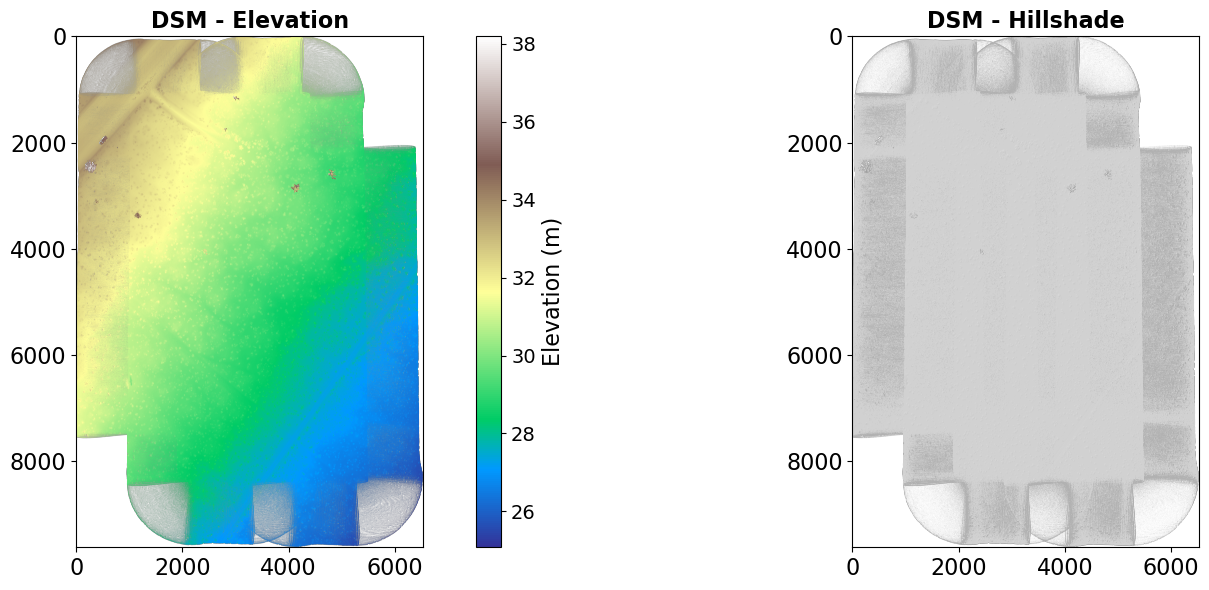


DSM STATISTICS
Dimensions: 6535 x 9623 pixels
Resolution: 0.0300 m/pixel
Elevation range: 25.08 to 38.19 m
Mean elevation: 29.61 m
Std deviation: 2.01 m


In [11]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource

# Load the DSM
# dsm_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
dsm_path = "/data/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif"

with rasterio.open(dsm_path) as src:
    dsm = src.read(1)
    nodata = src.nodata
    
    # Mask NoData values
    dsm_masked = np.ma.masked_equal(dsm, nodata) if nodata else dsm
    
    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(20, 6))
    for ax in axes:
        ax.tick_params(axis='both', which='major', labelsize=16)

    # 1. Elevation map
    im1 = axes[0].imshow(dsm_masked, cmap='terrain')
    
    axes[0].set_title('DSM - Elevation', fontsize=16, fontweight='bold')
    cbar = plt.colorbar(im1, ax=axes[0])
    cbar.set_label('Elevation (m)', fontsize=16)
    cbar.ax.tick_params(labelsize=14)
    
    # 2. Hillshade
    ls = LightSource(azdeg=315, altdeg=45)
    hillshade = ls.hillshade(dsm_masked, vert_exag=2)
    axes[1].imshow(hillshade, cmap='gray')
    axes[1].set_title('DSM - Hillshade', fontsize=16, fontweight='bold')
    
    # 3. Combined
    # axes[2].imshow(dsm_masked, cmap='terrain', alpha=0.7)
    # axes[2].imshow(hillshade, cmap='gray', alpha=0.3)
    # axes[2].set_title('DSM - Combined View', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n{'='*70}")
    print("DSM STATISTICS")
    print(f"{'='*70}")
    print(f"Dimensions: {src.width} x {src.height} pixels")
    print(f"Resolution: {src.res[0]:.4f} m/pixel")
    print(f"Elevation range: {dsm_masked.min():.2f} to {dsm_masked.max():.2f} m")
    print(f"Mean elevation: {dsm_masked.mean():.2f} m")
    print(f"Std deviation: {dsm_masked.std():.2f} m")

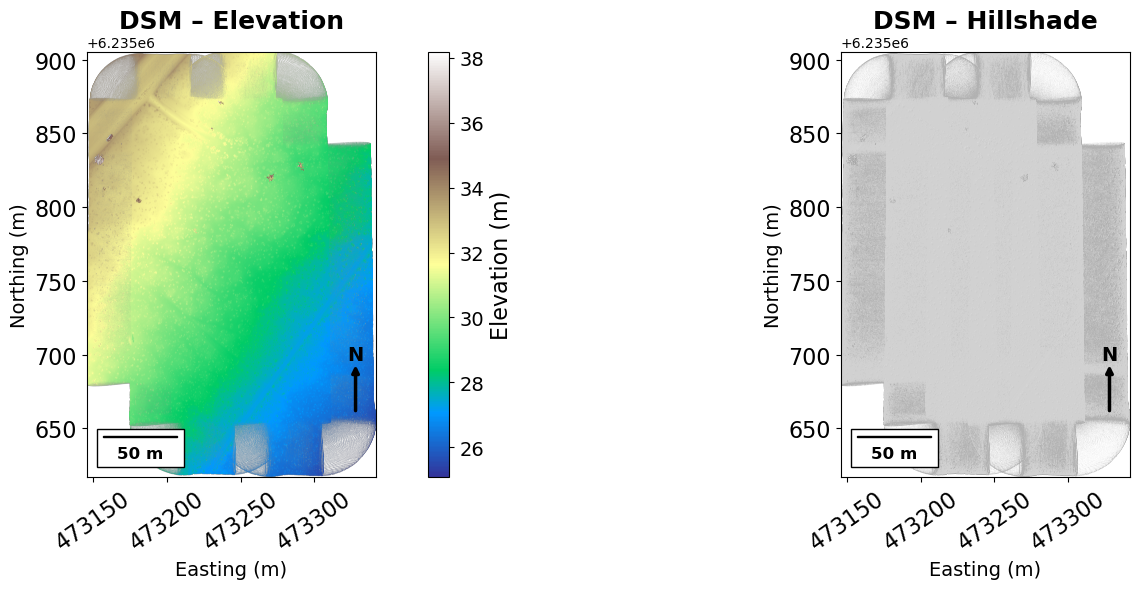


DSM STATISTICS
CRS             : COMPD_CS["GDA2020 / MGA zone 54 + AHD height",PROJCS["GDA2020 / MGA zone 54",GEOGCS["GDA2020",DATUM["Geocentric_Datum_of_Australia_2020",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","1168"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","7844"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",141],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","7854"]],VERT_CS["AHD height",VERT_DATUM["Australian Height Datum",2005,AUTHORITY["EPSG","5111"]],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Gravity-related height",UP],AUTHORITY["EPSG","5711"]]]
Bounds          : BoundingBox(left=473145.65999999986, bottom=6235616.839999774, right=473341.7

In [21]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LightSource
from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
import matplotlib.font_manager as fm
from math import atan2, degrees


# ---------------------------------------------------------------------
# Helper functions
# ---------------------------------------------------------------------

def nice_round_distance(x_m):
    """Round distance to 1/2/5 × 10^n (map-friendly)."""
    exp = 10 ** np.floor(np.log10(x_m))
    f = x_m / exp
    if f < 1.5:
        return 1 * exp
    elif f < 3.5:
        return 2 * exp
    elif f < 7.5:
        return 5 * exp
    else:
        return 10 * exp


def add_scalebar(ax, extent, fraction=0.2, location="lower left", fontsize=12):
    """
    Anchored, auto-scaling scale bar in m / km (extent-aware).
    """
    width_m = extent[1] - extent[0]  # right - left
    
    length_m = nice_round_distance(width_m * fraction)
    
    label = f"{length_m/1000:.1f} km" if length_m >= 1000 else f"{int(length_m)} m"
    label = label.replace(".0", "")

    fontprops = fm.FontProperties(size=fontsize, weight="bold")

    scalebar = AnchoredSizeBar(
        ax.transData,
        length_m,
        label,
        location,
        pad=0.4,
        borderpad=0.6,
        sep=6,
        frameon=True,
        size_vertical=length_m * 0.015,
        fontproperties=fontprops,
        color="black"
    )

    ax.add_artist(scalebar)


def add_north_arrow(ax, src, location=(0.93, 0.15), size=0.12):
    """
    Add a true-north arrow (CRS-aware, UTM-safe).
    """
    try:
        from pyproj import CRS, Transformer
        crs = CRS.from_user_input(src.crs)

        # Raster center
        cx = (src.bounds.left + src.bounds.right) / 2
        cy = (src.bounds.bottom + src.bounds.top) / 2

        # Convert to lon/lat
        transformer = Transformer.from_crs(crs, CRS.from_epsg(4326), always_xy=True)
        lon, lat = transformer.transform(cx, cy)

        # Meridian convergence (grid → true north)
        factors = crs.get_factors(lon, lat)
        convergence = factors.meridian_convergence or 0.0

    except Exception:
        convergence = 0.0

    # Raster rotation from affine
    transform = src.transform
    raster_rotation = degrees(atan2(transform.d, transform.a))

    net_rotation = np.deg2rad(convergence - raster_rotation)

    dx = size * np.sin(net_rotation)
    dy = size * np.cos(net_rotation)

    x, y = location

    ax.annotate(
        "",
        xy=(x + dx, y + dy),
        xytext=(x, y),
        xycoords="axes fraction",
        arrowprops=dict(arrowstyle="-|>", lw=2.5, color="black")
    )

    ax.text(
        x + dx * 1.15,
        y + dy * 1.15,
        "N",
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="center",
        va="center"
    )


# ---------------------------------------------------------------------
# Load DSM
# ---------------------------------------------------------------------

# dsm_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"
dsm_path = "/data/calperumResearch/site2_1_DD0011/lidar/dsm/SASMDD0011_l1_dsm_03.tif"

with rasterio.open(dsm_path) as src:
    dsm = src.read(1)
    nodata = src.nodata
    pixel_size = src.res[0]  # metres per pixel
    crs = src.crs  # Get CRS
    
    # Calculate extent from bounds: (left, right, bottom, top)
    extent = [src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top]

    dsm_masked = np.ma.masked_equal(dsm, nodata) if nodata is not None else dsm

    # -----------------------------------------------------------------
    # Plot
    # -----------------------------------------------------------------

    fig, axes = plt.subplots(1, 2, figsize=(20, 6))

    for ax in axes:
        ax.tick_params(axis="both", labelsize=16)
        # Rotate X-axis labels
        ax.tick_params(axis="x", rotation=35)

    # Elevation
    im = axes[0].imshow(dsm_masked, cmap="terrain", extent=extent, origin='upper')
    axes[0].set_title("DSM – Elevation", fontsize=18, fontweight="bold")
    axes[0].set_xlabel("Easting (m)", fontsize=14)
    axes[0].set_ylabel("Northing (m)", fontsize=14)

    cbar = plt.colorbar(im, ax=axes[0])
    cbar.set_label("Elevation (m)", fontsize=16)
    cbar.ax.tick_params(labelsize=14)

    add_scalebar(axes[0], extent, fraction=0.2)
    add_north_arrow(axes[0], src)

    # Hillshade
    ls = LightSource(azdeg=315, altdeg=45)
    hillshade = ls.hillshade(dsm_masked, vert_exag=2)

    axes[1].imshow(hillshade, cmap="gray", extent=extent, origin='upper')
    axes[1].set_title("DSM – Hillshade", fontsize=18, fontweight="bold")
    axes[1].set_xlabel("Easting (m)", fontsize=14)
    axes[1].set_ylabel("Northing (m)", fontsize=14)

    add_scalebar(axes[1], extent, fraction=0.2)
    add_north_arrow(axes[1], src)

    plt.tight_layout()
    plt.show()

    # -----------------------------------------------------------------
    # Statistics
    # -----------------------------------------------------------------

    print("\n" + "=" * 70)
    print("DSM STATISTICS")
    print("=" * 70)
    print(f"CRS             : {crs}")
    print(f"Bounds          : {src.bounds}")
    print(f"Dimensions      : {src.width} x {src.height} pixels")
    print(f"Resolution      : {pixel_size:.3f} m / pixel")
    print(f"Elevation range : {dsm_masked.min():.2f} – {dsm_masked.max():.2f} m")
    print(f"Mean elevation  : {dsm_masked.mean():.2f} m")
    print(f"Std deviation   : {dsm_masked.std():.2f} m")

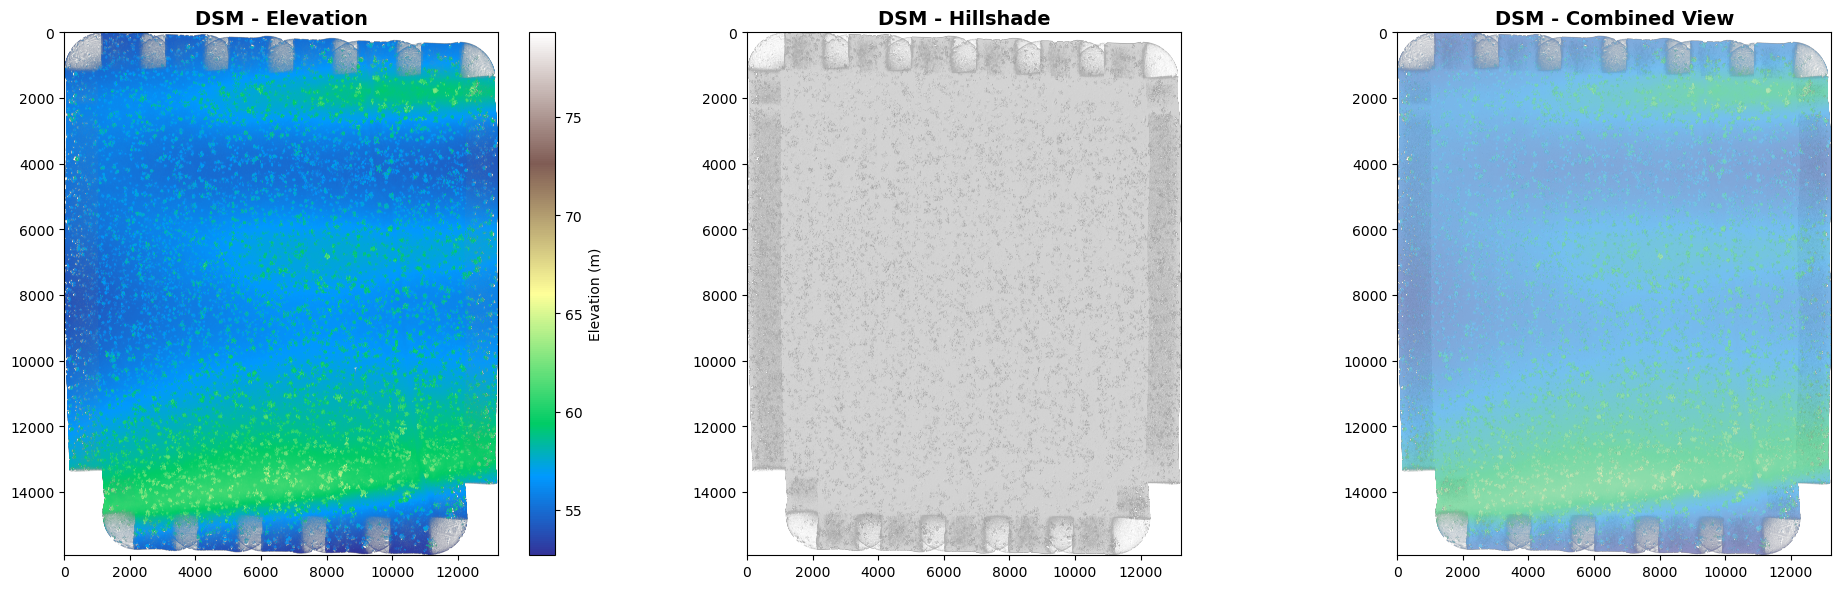


DSM STATISTICS
Dimensions: 13234 x 15933 pixels
Resolution: 0.0300 m/pixel
Elevation range: 52.69 to 79.30 m
Mean elevation: 56.99 m
Std deviation: 1.72 m


In [5]:
import rasterio
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource

# Load the DSM
dsm_path = "/data/calperumResearch/site1_1_DD0001/lidar/dsm/SASMDD0001_l1_dsm_03.tif"

with rasterio.open(dsm_path) as src:
    dsm = src.read(1)
    nodata = src.nodata
    
    # Mask NoData values
    dsm_masked = np.ma.masked_equal(dsm, nodata) if nodata else dsm
    
    # Create visualization
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    
    # 1. Elevation map
    im1 = axes[0].imshow(dsm_masked, cmap='terrain')
    axes[0].set_title('DSM - Elevation', fontsize=14, fontweight='bold')
    plt.colorbar(im1, ax=axes[0], label='Elevation (m)')
    
    # 2. Hillshade
    ls = LightSource(azdeg=315, altdeg=45)
    hillshade = ls.hillshade(dsm_masked, vert_exag=2)
    axes[1].imshow(hillshade, cmap='gray')
    axes[1].set_title('DSM - Hillshade', fontsize=14, fontweight='bold')
    
    # 3. Combined
    axes[2].imshow(dsm_masked, cmap='terrain', alpha=0.7)
    axes[2].imshow(hillshade, cmap='gray', alpha=0.3)
    axes[2].set_title('DSM - Combined View', fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n{'='*70}")
    print("DSM STATISTICS")
    print(f"{'='*70}")
    print(f"Dimensions: {src.width} x {src.height} pixels")
    print(f"Resolution: {src.res[0]:.4f} m/pixel")
    print(f"Elevation range: {dsm_masked.min():.2f} to {dsm_masked.max():.2f} m")
    print(f"Mean elevation: {dsm_masked.mean():.2f} m")
    print(f"Std deviation: {dsm_masked.std():.2f} m")

## 6) Optional: predefined site configs

`SITE_CONFIGS` in the module (dsm_lidar.py scripts) is a convenience dictionary for common inputs/outputs.

In [5]:
print("Available site configurations:")
for name in SITE_CONFIGS:
    print(f"  - {name}")

# Example:
site = "DD0011_L2"
cfg = SITE_CONFIGS[site]
print(f"\nExample config for {site}:")
print(cfg)


Available site configurations:
  - DD0001_L1
  - DD0011_L1
  - DD0001_L2
  - DD0011_L2
  - DD0001_Riegl

Example config for DD0011_L2:
{'input': '/data/calperumResearch/site2_1_DD0011/lidar_l2/cloud3358f88f2d9dc868.las', 'output': '/data/calperumResearch/site2_1_DD0011/lidar_l2/dsm/SASMDD0011_l2_dsm_03.tif', 'site_id': 'DD0011', 'level': 'L2'}
